# DATA ANALYSIS AND RESULTS

importing required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('ggplot')

#For ignoring warning
import warnings
warnings.filterwarnings("ignore")

Importing data

In [2]:
data = pd.read_csv('insurance_dataset.csv')

In [3]:
data.head(2)

,age,gender,bmi,children,smoker,region,medical_history,family_medical_history,exercise_frequency,occupation,coverage_level,charges
0,46,male,21.45,5,yes,southeast,Diabetes,None,Never,Blue collar,Premium,20460.307669
1,25,female,25.38,2,yes,northwest,Diabetes,High blood pressure,Occasionally,White collar,Premium,20390.899218


### Exploratory Data Analysis

Checking for missing values

In [4]:
data.isnull().sum()

age                       0
gender                    0
bmi                       0
children                  0
smoker                    0
region                    0
medical_history           0
family_medical_history    0
exercise_frequency        0
occupation                0
coverage_level            0
charges                   0
dtype: int64

checking for duplicates

In [5]:
data.duplicated().sum()

0

In [6]:
data.drop_duplicates()

,age,gender,bmi,children,smoker,region,medical_history,family_medical_history,exercise_frequency,occupation,coverage_level,charges
0,46,male,21.45,5,yes,southeast,Diabetes,None,Never,Blue collar,Premium,20460.307669
1,25,female,25.38,2,yes,northwest,Diabetes,High blood pressure,Occasionally,White collar,Premium,20390.899218
2,38,male,44.88,2,yes,southwest,None,High blood pressure,Occasionally,Blue collar,Premium,20204.476302
3,25,male,19.89,0,no,northwest,None,Diabetes,Rarely,White collar,Standard,11789.029843
4,49,male,38.21,3,yes,northwest,Diabetes,High blood pressure,Rarely,White collar,Standard,19268.309838
...,...,...,...,...,...,...,...,...,...,...,...,...
999995,59,male,46.67,2,no,northeast,High blood pressure,None,Frequently,Student,Basic,11584.134900
999996,33,male,36.83,2,no,northeast,None,High blood pressure,Frequently,Unemployed,Basic,9834.871456
999997,39,male,39.84,0,yes,northeast,Heart disease,High blood pressure,Rarely,Blue collar,Standard,22076.632856
999998,37,female,45.06,4,yes,northeast,High blood pressure,Diabetes,Occasionally,Unemployed,Premium,20297.618728


Shape if the data

In [7]:
data.shape

(1000000, 12)

data types

In [8]:
data.dtypes

age                         int64
gender                     object
bmi                       float64
children                    int64
smoker                     object
region                     object
medical_history            object
family_medical_history     object
exercise_frequency         object
occupation                 object
coverage_level             object
charges                   float64
dtype: object

Descriptive statisticss for continous and categorical variables

In [9]:
#Summary Statistics for continous features
continous_feat = data.columns[data.nunique()  > 4]
data[continous_feat].describe().T

,count,mean,std,min,25%,50%,75%,max
age,1000000.0,41.495282,13.855189,18.000000,29.000000,41.000000,53.00000,65.000000
bmi,1000000.0,34.001839,9.231680,18.000000,26.020000,34.000000,41.99000,50.000000
children,1000000.0,2.499886,1.707679,0.000000,1.000000,2.000000,4.00000,5.000000
charges,1000000.0,16735.117481,4415.808211,3445.011643,13600.372379,16622.127973,19781.46541,32561.560374


In [10]:
#Summary Statistics for categorical features
cat_col = data.columns[(data.nunique()  < 5)]
data[cat_col].describe().T

,count,unique,top,freq
gender,1000000,2,male,500107
smoker,1000000,2,yes,500129
region,1000000,4,northeast,250343
medical_history,1000000,4,None,250762
family_medical_history,1000000,4,None,250404
exercise_frequency,1000000,4,Rarely,250538
occupation,1000000,4,Unemployed,250571
coverage_level,1000000,3,Basic,333515


Coverage Level

In [11]:
data['coverage_level'].value_counts()

Basic       333515
Standard    333508
Premium     332977
Name: coverage_level, dtype: int64

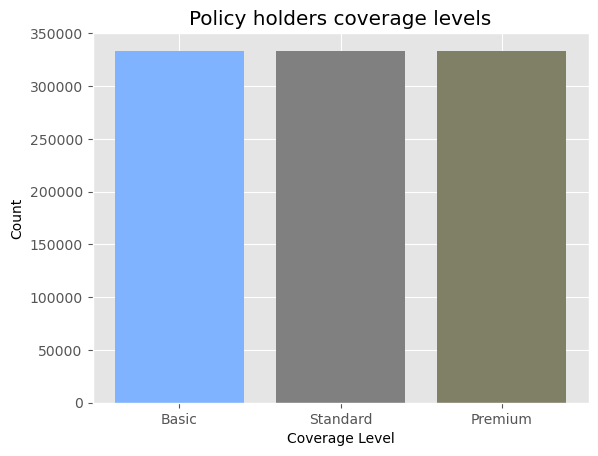

In [12]:
# Data
labels = ['Basic', 'Standard', 'Premium']
values = [333515, 333508, 332977]

# Light blue and green colors (RGB values)
light_blue = (0.5, 0.7, 1.0)  # Light blue color
light_green = (0.5, 0.5, 0.5)  # Light green color
army_green = (0.5, 0.5, 0.4)

# Plotting
plt.bar(labels, values, color=[light_blue, light_green, army_green])
plt.xlabel('Coverage Level')
plt.ylabel('Count')
plt.title('Policy holders coverage levels')
plt.show()

Gender distribution

In [13]:
data['gender'].value_counts()

male      500107
female    499893
Name: gender, dtype: int64

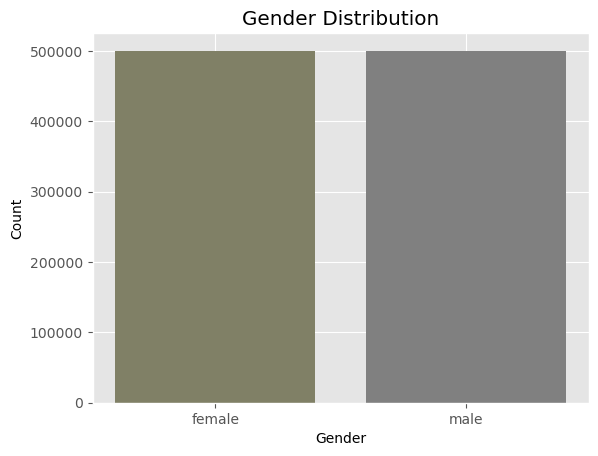

In [14]:
# Count occurrences of each unique value
value_counts = data['gender'].value_counts()
unique_values = ['female', 'male']

light_blue = (0.5, 0.5, 0.4)  
light_green = (0.5, 0.5, 0.5)  

# Plotting
plt.bar(unique_values, value_counts, color= [light_blue, light_green])  # You can customize the colors as needed
plt.xlabel('Gender')
plt.ylabel('Count')
plt.title('Gender Distribution')
plt.show()

Coverage Levels according to gender

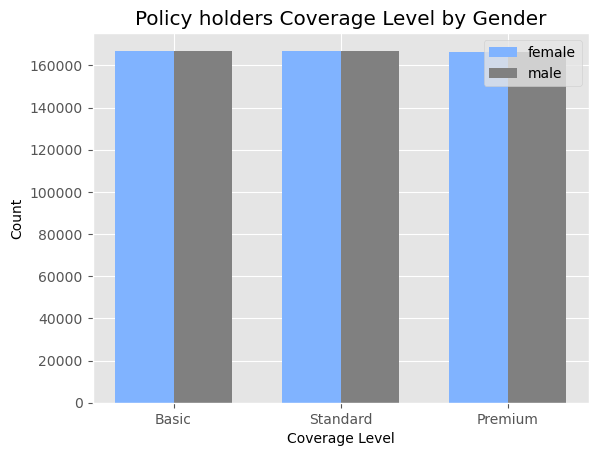

In [15]:
# Count occurrences of each unique value for gender
gender_counts = data['gender'].value_counts()
unique_genders = ['female', 'male']

# Count occurrences of satisfaction by gender
satisfaction_counts_female = data[data['gender'] == 'female']['coverage_level'].value_counts()
satisfaction_counts_male = data[data['gender'] == 'male']['coverage_level'].value_counts()

# Light blue and green colors for satisfaction bars
light_blue = (0.5, 0.7, 1.0)  
light_green = (0.5, 0.5, 0.5) 
army_green = (0.5, 0.5, 0.4)

# Plotting
labels = ['Basic', 'Standard', 'Premium']
x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots()

# Plot satisfaction by gender
ax.bar(x - width/2, satisfaction_counts_female, width, label='female', color=light_blue)
ax.bar(x + width/2, satisfaction_counts_male, width, label='male', color=light_green)

# Add some text for labels, title, and legend
ax.set_xlabel('Coverage Level')
ax.set_ylabel('Count')
ax.set_title('Policy holders Coverage Level by Gender')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.show()

Age distribution

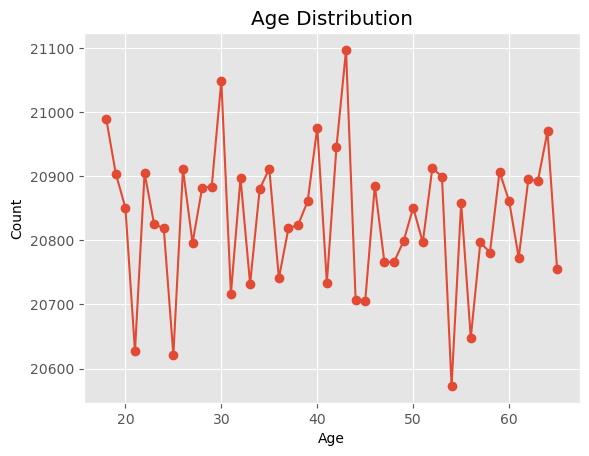

In [16]:
# Filter unique ages from the DataFrame
unique_ages = data['age'].unique()
unique_ages.sort()

# Calculate counts for each unique age
counts = [data[data['age'] == age]['age'].count() for age in unique_ages]

# Plotting
plt.plot(unique_ages, counts, marker='o', linestyle='-')
plt.xlabel('Age')
plt.ylabel('Count')
plt.title('Age Distribution')
plt.grid(True)  # Add grid lines
plt.show()

Age distribution of Basic, Standard and Premium coverage levels

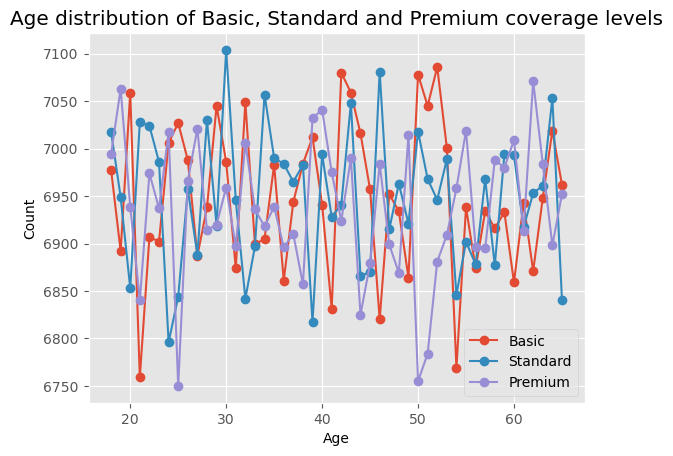

In [17]:
# Filter data for satisfied and dissatisfied customers
basic = data[data['coverage_level'] == 'Basic']
standard = data[data['coverage_level'] == 'Standard']
premium = data[data['coverage_level'] == 'Premium']

# Calculate counts for each unique age for satisfied and dissatisfied customers
unique_ages_basic = sorted(basic['age'].unique())
unique_ages_standard = sorted(standard['age'].unique())
unique_ages_premium = sorted(premium['age'].unique())
counts_basic = [basic[basic['age'] == age]['age'].count() for age in unique_ages_basic]
counts_standard = [standard[standard['age'] == age]['age'].count() for age in unique_ages_standard]
counts_premium = [premium[premium['age'] == age]['age'].count() for age in unique_ages_premium]

# Plotting
plt.plot(unique_ages_basic, counts_basic, marker='o', linestyle='-', label='Basic')
plt.plot(unique_ages_standard, counts_standard, marker='o', linestyle='-', label='Standard')
plt.plot(unique_ages_premium, counts_premium, marker='o', linestyle='-', label='Premium')
plt.xlabel('Age')
plt.ylabel('Count')
plt.title('Age distribution of Basic, Standard and Premium coverage levels')
plt.legend()
plt.grid(True)  # Add grid lines
plt.show()

BMI distribution of Basic, Standard and Premium coverage levels

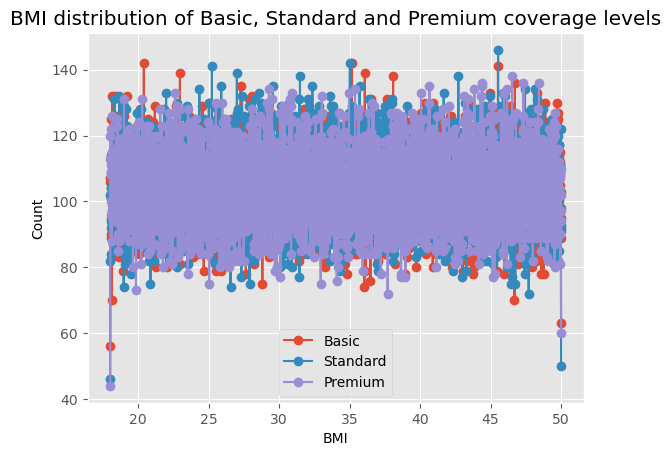

In [18]:
# Filter data for satisfied and dissatisfied customers
basic = data[data['coverage_level'] == 'Basic']
standard = data[data['coverage_level'] == 'Standard']
premium = data[data['coverage_level'] == 'Premium']

# Calculate counts for each unique age for satisfied and dissatisfied customers
unique_ages_basic = sorted(basic['bmi'].unique())
unique_ages_standard = sorted(standard['bmi'].unique())
unique_ages_premium = sorted(premium['bmi'].unique())
counts_basic = [basic[basic['bmi'] == age]['bmi'].count() for age in unique_ages_basic]
counts_standard = [standard[standard['bmi'] == age]['bmi'].count() for age in unique_ages_standard]
counts_premium = [premium[premium['bmi'] == age]['bmi'].count() for age in unique_ages_premium]

# Plotting
plt.plot(unique_ages_basic, counts_basic, marker='o', linestyle='-', label='Basic')
plt.plot(unique_ages_standard, counts_standard, marker='o', linestyle='-', label='Standard')
plt.plot(unique_ages_premium, counts_premium, marker='o', linestyle='-', label='Premium')
plt.xlabel('BMI')
plt.ylabel('Count')
plt.title('BMI distribution of Basic, Standard and Premium coverage levels')
plt.legend()
plt.grid(True)  # Add grid lines
plt.show()

BMI and Age vs Coverage level

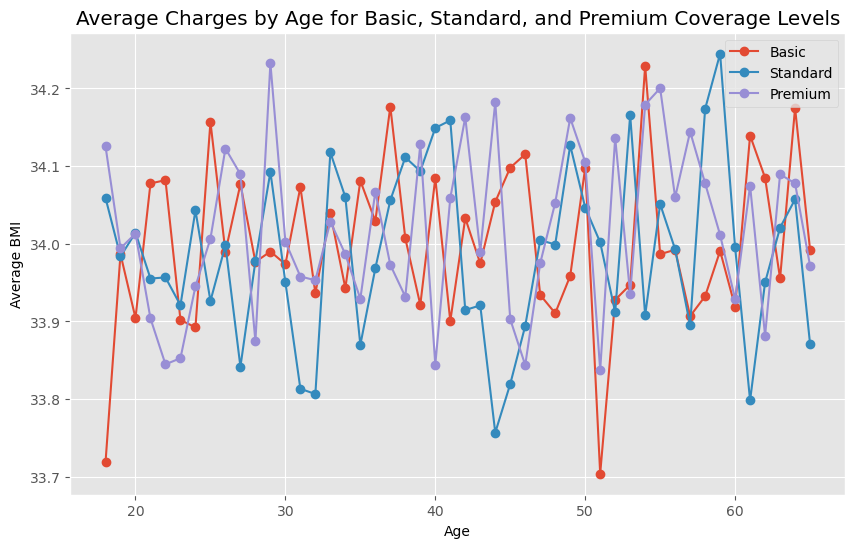

In [19]:
# Filter data for each coverage level
basic = data[data['coverage_level'] == 'Basic']
standard = data[data['coverage_level'] == 'Standard']
premium = data[data['coverage_level'] == 'Premium']

# Calculate average charges for each unique age for each coverage level
unique_ages_basic = sorted(basic['age'].unique())
unique_ages_standard = sorted(standard['age'].unique())
unique_ages_premium = sorted(premium['age'].unique())
average_charges_basic = [basic[basic['age'] == age]['bmi'].mean() for age in unique_ages_basic]
average_charges_standard = [standard[standard['age'] == age]['bmi'].mean() for age in unique_ages_standard]
average_charges_premium = [premium[premium['age'] == age]['bmi'].mean() for age in unique_ages_premium]

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(unique_ages_basic, average_charges_basic, marker='o', linestyle='-', label='Basic')
plt.plot(unique_ages_standard, average_charges_standard, marker='o', linestyle='-', label='Standard')
plt.plot(unique_ages_premium, average_charges_premium, marker='o', linestyle='-', label='Premium')

# Add some text for labels and title
plt.xlabel('Age')
plt.ylabel('Average BMI')
plt.title('Average Charges by Age for Basic, Standard, and Premium Coverage Levels')
plt.legend()
plt.grid(True)  # Add grid lines

# Show plot
plt.show()

Smokers and Non smokers

In [20]:
data['smoker'].value_counts()

yes    500129
no     499871
Name: smoker, dtype: int64

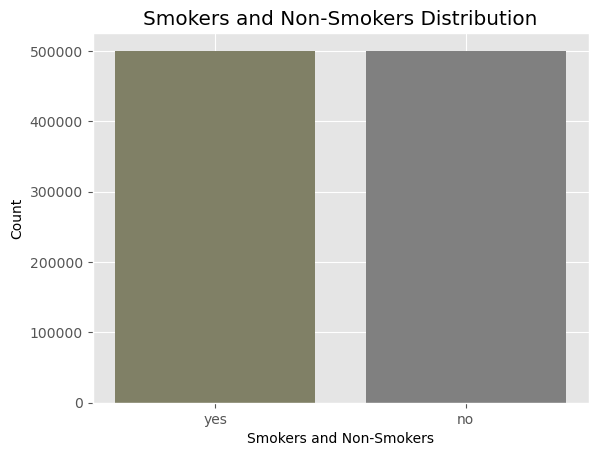

In [21]:
# Count occurrences of each unique value
value_counts = data['smoker'].value_counts()
unique_values = ['yes', 'no']

light_blue = (0.5, 0.5, 0.4)  
light_green = (0.5, 0.5, 0.5)  

# Plotting
plt.bar(unique_values, value_counts, color= [light_blue, light_green])  # You can customize the colors as needed
plt.xlabel('Smokers and Non-Smokers')
plt.ylabel('Count')
plt.title('Smokers and Non-Smokers Distribution')
plt.show()

Smokers and Non-Smokers vs Coverage Levels

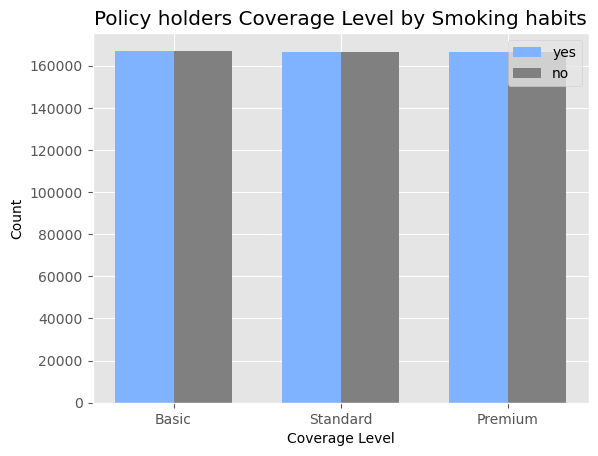

In [22]:
# Count occurrences of each unique value for gender
gender_counts = data['smoker'].value_counts()
unique_genders = ['yes', 'no']

# Count occurrences of satisfaction by gender
satisfaction_counts_female = data[data['smoker'] == 'yes']['coverage_level'].value_counts()
satisfaction_counts_male = data[data['smoker'] == 'no']['coverage_level'].value_counts()

# Light blue and green colors for satisfaction bars
light_blue = (0.5, 0.7, 1.0)  
light_green = (0.5, 0.5, 0.5) 
army_green = (0.5, 0.5, 0.4)

# Plotting
labels = ['Basic', 'Standard', 'Premium']
x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots()

# Plot satisfaction by gender
ax.bar(x - width/2, satisfaction_counts_female, width, label='yes', color=light_blue)
ax.bar(x + width/2, satisfaction_counts_male, width, label='no', color=light_green)

# Add some text for labels, title, and legend
ax.set_xlabel('Coverage Level')
ax.set_ylabel('Count')
ax.set_title('Policy holders Coverage Level by Smoking habits')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.show()

Medical History

In [23]:
data['medical_history'].value_counts()

None                   250762
Heart disease          250121
High blood pressure    249782
Diabetes               249335
Name: medical_history, dtype: int64

Medical history and Coverage Levels

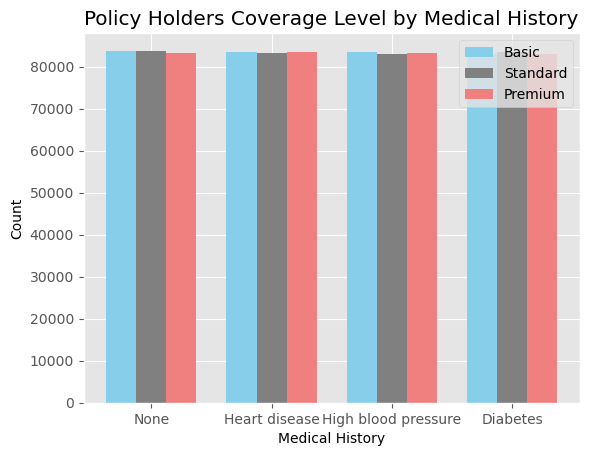

In [24]:
# Count occurrences of each unique value for gender
cov_counts = data['coverage_level'].value_counts()
unique_cov = ['Basic', 'Standard', 'Premium']

# Count occurrences of satisfaction by coverage level
satisfaction_counts_basic = data[data['coverage_level'] == 'Basic']['medical_history'].value_counts()
satisfaction_counts_standard = data[data['coverage_level'] == 'Standard']['medical_history'].value_counts()
satisfaction_counts_premium = data[data['coverage_level'] == 'Premium']['medical_history'].value_counts()

# Align counts with the labels
labels = ['None', 'Heart disease', 'High blood pressure', 'Diabetes']
satisfaction_counts_basic = satisfaction_counts_basic.reindex(labels, fill_value=0)
satisfaction_counts_standard = satisfaction_counts_standard.reindex(labels, fill_value=0)
satisfaction_counts_premium = satisfaction_counts_premium.reindex(labels, fill_value=0)

# Colors for the bars
color_basic = 'skyblue'  
color_standard = 'grey' 
color_premium = 'lightcoral'

# Plotting
x = np.arange(len(labels))  # the label locations
width = 0.25  # the width of the bars

fig, ax = plt.subplots()

# Plot satisfaction by coverage level
ax.bar(x - width, satisfaction_counts_basic, width, label='Basic', color=color_basic)
ax.bar(x, satisfaction_counts_standard, width, label='Standard', color=color_standard)
ax.bar(x + width, satisfaction_counts_premium, width, label='Premium', color=color_premium)

# Add some text for labels, title, and legend
ax.set_xlabel('Medical History')
ax.set_ylabel('Count')
ax.set_title('Policy Holders Coverage Level by Medical History')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.show()

Family medical history

In [25]:
data['family_medical_history'].value_counts()

None                   250404
Heart disease          250035
High blood pressure    249824
Diabetes               249737
Name: family_medical_history, dtype: int64

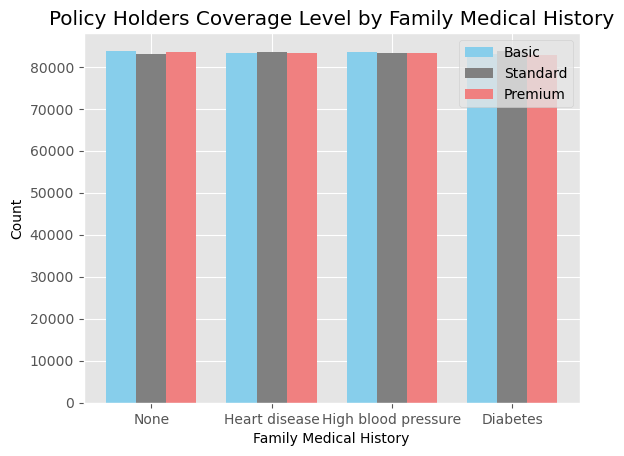

In [26]:
# Count occurrences of each unique value for gender
cov_counts = data['coverage_level'].value_counts()
unique_cov = ['Basic', 'Standard', 'Premium']

# Count occurrences of satisfaction by coverage level
satisfaction_counts_basic = data[data['coverage_level'] == 'Basic']['family_medical_history'].value_counts()
satisfaction_counts_standard = data[data['coverage_level'] == 'Standard']['family_medical_history'].value_counts()
satisfaction_counts_premium = data[data['coverage_level'] == 'Premium']['family_medical_history'].value_counts()

# Align counts with the labels
labels = ['None', 'Heart disease', 'High blood pressure', 'Diabetes']
satisfaction_counts_basic = satisfaction_counts_basic.reindex(labels, fill_value=0)
satisfaction_counts_standard = satisfaction_counts_standard.reindex(labels, fill_value=0)
satisfaction_counts_premium = satisfaction_counts_premium.reindex(labels, fill_value=0)

# Colors for the bars
color_basic = 'skyblue'  
color_standard = 'grey' 
color_premium = 'lightcoral'

# Plotting
x = np.arange(len(labels))  # the label locations
width = 0.25  # the width of the bars

fig, ax = plt.subplots()

# Plot satisfaction by coverage level
ax.bar(x - width, satisfaction_counts_basic, width, label='Basic', color=color_basic)
ax.bar(x, satisfaction_counts_standard, width, label='Standard', color=color_standard)
ax.bar(x + width, satisfaction_counts_premium, width, label='Premium', color=color_premium)

# Add some text for labels, title, and legend
ax.set_xlabel('Family Medical History')
ax.set_ylabel('Count')
ax.set_title('Policy Holders Coverage Level by Family Medical History')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.show()

Region

In [27]:
data['region'].value_counts()

northeast    250343
southwest    250095
northwest    249931
southeast    249631
Name: region, dtype: int64

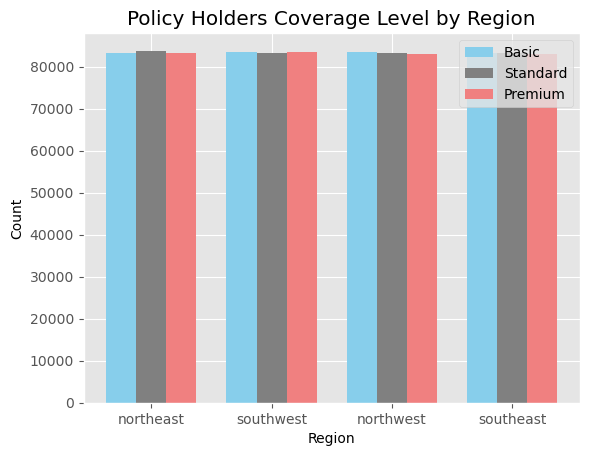

In [28]:
# Count occurrences of each unique value for gender
cov_counts = data['coverage_level'].value_counts()
unique_cov = ['Basic', 'Standard', 'Premium']

# Count occurrences of satisfaction by coverage level
satisfaction_counts_basic = data[data['coverage_level'] == 'Basic']['region'].value_counts()
satisfaction_counts_standard = data[data['coverage_level'] == 'Standard']['region'].value_counts()
satisfaction_counts_premium = data[data['coverage_level'] == 'Premium']['region'].value_counts()

# Align counts with the labels
labels = ['northeast', 'southwest', 'northwest', 'southeast']
satisfaction_counts_basic = satisfaction_counts_basic.reindex(labels, fill_value=0)
satisfaction_counts_standard = satisfaction_counts_standard.reindex(labels, fill_value=0)
satisfaction_counts_premium = satisfaction_counts_premium.reindex(labels, fill_value=0)

# Colors for the bars
color_basic = 'skyblue'  
color_standard = 'grey' 
color_premium = 'lightcoral'

# Plotting
x = np.arange(len(labels))  # the label locations
width = 0.25  # the width of the bars

fig, ax = plt.subplots()

# Plot satisfaction by coverage level
ax.bar(x - width, satisfaction_counts_basic, width, label='Basic', color=color_basic)
ax.bar(x, satisfaction_counts_standard, width, label='Standard', color=color_standard)
ax.bar(x + width, satisfaction_counts_premium, width, label='Premium', color=color_premium)

# Add some text for labels, title, and legend
ax.set_xlabel('Region')
ax.set_ylabel('Count')
ax.set_title('Policy Holders Coverage Level by Region')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.show()

Exercise frequency

In [29]:
data['exercise_frequency'].value_counts()

Rarely          250538
Occasionally    250362
Frequently      249746
Never           249354
Name: exercise_frequency, dtype: int64

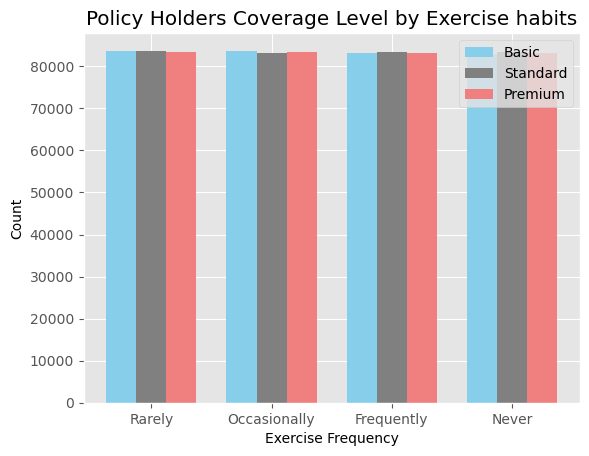

In [30]:
# Count occurrences of each unique value for gender
cov_counts = data['coverage_level'].value_counts()
unique_cov = ['Basic', 'Standard', 'Premium']

# Count occurrences of satisfaction by coverage level
satisfaction_counts_basic = data[data['coverage_level'] == 'Basic']['exercise_frequency'].value_counts()
satisfaction_counts_standard = data[data['coverage_level'] == 'Standard']['exercise_frequency'].value_counts()
satisfaction_counts_premium = data[data['coverage_level'] == 'Premium']['exercise_frequency'].value_counts()

# Align counts with the labels
labels = ['Rarely', 'Occasionally', 'Frequently', 'Never']
satisfaction_counts_basic = satisfaction_counts_basic.reindex(labels, fill_value=0)
satisfaction_counts_standard = satisfaction_counts_standard.reindex(labels, fill_value=0)
satisfaction_counts_premium = satisfaction_counts_premium.reindex(labels, fill_value=0)

# Colors for the bars
color_basic = 'skyblue'  
color_standard = 'grey' 
color_premium = 'lightcoral'

# Plotting
x = np.arange(len(labels))  # the label locations
width = 0.25  # the width of the bars

fig, ax = plt.subplots()

# Plot satisfaction by coverage level
ax.bar(x - width, satisfaction_counts_basic, width, label='Basic', color=color_basic)
ax.bar(x, satisfaction_counts_standard, width, label='Standard', color=color_standard)
ax.bar(x + width, satisfaction_counts_premium, width, label='Premium', color=color_premium)

# Add some text for labels, title, and legend
ax.set_xlabel('Exercise Frequency')
ax.set_ylabel('Count')
ax.set_title('Policy Holders Coverage Level by Exercise habits')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.show()

Occupation

In [31]:
data['occupation'].value_counts()

Unemployed      250571
Student         250279
Blue collar     249825
White collar    249325
Name: occupation, dtype: int64

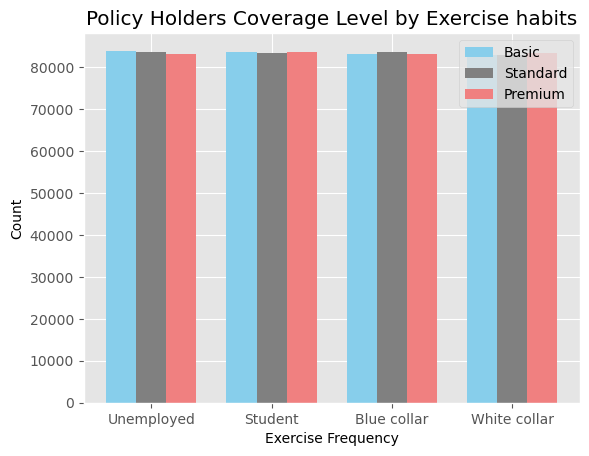

In [32]:
# Count occurrences of each unique value for gender
cov_counts = data['coverage_level'].value_counts()
unique_cov = ['Basic', 'Standard', 'Premium']

# Count occurrences of satisfaction by coverage level
satisfaction_counts_basic = data[data['coverage_level'] == 'Basic']['occupation'].value_counts()
satisfaction_counts_standard = data[data['coverage_level'] == 'Standard']['occupation'].value_counts()
satisfaction_counts_premium = data[data['coverage_level'] == 'Premium']['occupation'].value_counts()

# Align counts with the labels
labels = ['Unemployed', 'Student', 'Blue collar', 'White collar']
satisfaction_counts_basic = satisfaction_counts_basic.reindex(labels, fill_value=0)
satisfaction_counts_standard = satisfaction_counts_standard.reindex(labels, fill_value=0)
satisfaction_counts_premium = satisfaction_counts_premium.reindex(labels, fill_value=0)

# Colors for the bars
color_basic = 'skyblue'  
color_standard = 'grey' 
color_premium = 'lightcoral'

# Plotting
x = np.arange(len(labels))  # the label locations
width = 0.25  # the width of the bars

fig, ax = plt.subplots()

# Plot satisfaction by coverage level
ax.bar(x - width, satisfaction_counts_basic, width, label='Basic', color=color_basic)
ax.bar(x, satisfaction_counts_standard, width, label='Standard', color=color_standard)
ax.bar(x + width, satisfaction_counts_premium, width, label='Premium', color=color_premium)

# Add some text for labels, title, and legend
ax.set_xlabel('Exercise Frequency')
ax.set_ylabel('Count')
ax.set_title('Policy Holders Coverage Level by Exercise habits')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.show()

Average premium charges by age for basic, standard and premium coverage levels

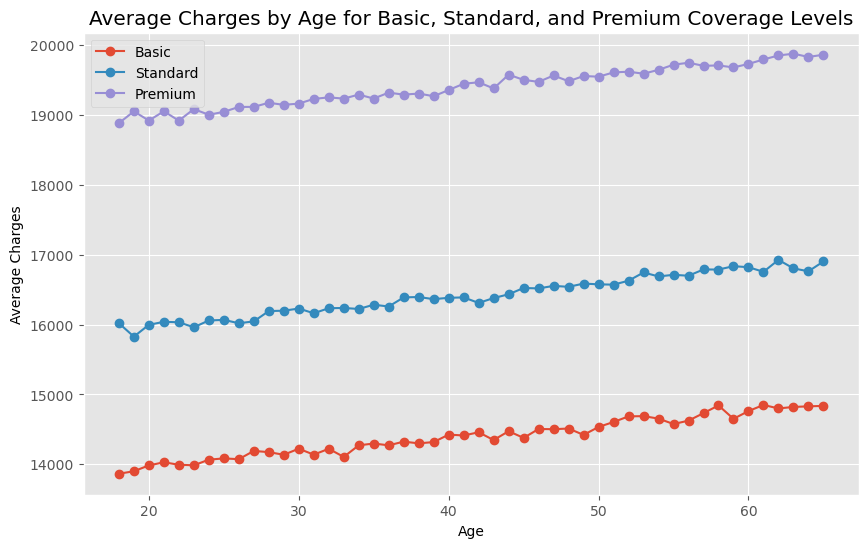

In [33]:
# Filter data for each coverage level
basic = data[data['coverage_level'] == 'Basic']
standard = data[data['coverage_level'] == 'Standard']
premium = data[data['coverage_level'] == 'Premium']

# Calculate average charges for each unique age for each coverage level
unique_ages_basic = sorted(basic['age'].unique())
unique_ages_standard = sorted(standard['age'].unique())
unique_ages_premium = sorted(premium['age'].unique())
average_charges_basic = [basic[basic['age'] == age]['charges'].mean() for age in unique_ages_basic]
average_charges_standard = [standard[standard['age'] == age]['charges'].mean() for age in unique_ages_standard]
average_charges_premium = [premium[premium['age'] == age]['charges'].mean() for age in unique_ages_premium]

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(unique_ages_basic, average_charges_basic, marker='o', linestyle='-', label='Basic')
plt.plot(unique_ages_standard, average_charges_standard, marker='o', linestyle='-', label='Standard')
plt.plot(unique_ages_premium, average_charges_premium, marker='o', linestyle='-', label='Premium')

# Add some text for labels and title
plt.xlabel('Age')
plt.ylabel('Average Charges')
plt.title('Average Charges by Age for Basic, Standard, and Premium Coverage Levels')
plt.legend()
plt.grid(True)  # Add grid lines

# Show plot
plt.show()

### Data preprocessing

#### Feature Engineering

Encoding categorical variables

In [34]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [35]:
# Identify the categorical columns
categorical_cols = ['gender', 'coverage_level', 'occupation', 'smoker',
                    'region', 'medical_history', 'family_medical_history', 'exercise_frequency']

# Initialize the LabelEncoder
label_encoders = {}

# Apply LabelEncoder to each categorical column
for col in categorical_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le

In [36]:
data.head()

,age,gender,bmi,children,smoker,region,medical_history,family_medical_history,exercise_frequency,occupation,coverage_level,charges
0,46,1,21.45,5,1,2,0,3,1,0,1,20460.307669
1,25,0,25.38,2,1,1,0,2,2,3,1,20390.899218
2,38,1,44.88,2,1,3,3,2,2,0,1,20204.476302
3,25,1,19.89,0,0,1,3,0,3,3,2,11789.029843
4,49,1,38.21,3,1,1,0,2,3,3,2,19268.309838


Scaling continuous variables

In [37]:
continuous_cols = ['age', 'bmi']

scaler = StandardScaler()
scaled_continuous = scaler.fit_transform(data[continuous_cols])

# Create a new DataFrame with scaled continuous columns and encoded categorical columns
scaled_df = data[categorical_cols].copy()
scaled_continuous_df = pd.DataFrame(scaled_continuous, columns=continuous_cols)
scaled_df = pd.concat([scaled_df, scaled_continuous_df, data[['children', 'charges']]], axis=1)


In [38]:
scaled_df.head()

,gender,coverage_level,occupation,smoker,region,medical_history,family_medical_history,exercise_frequency,age,bmi,children,charges
0,1,1,0,1,2,0,3,1,0.325129,-1.359649,5,20460.307669
1,0,1,3,1,1,0,2,2,-1.190550,-0.933941,2,20390.899218
2,1,1,0,1,3,3,2,2,-0.252273,1.178352,2,20204.476302
3,1,2,3,0,1,3,0,3,-1.190550,-1.528632,0,11789.029843
4,1,2,3,1,1,0,2,3,0.541654,0.455839,3,19268.309838


#### Feature selection

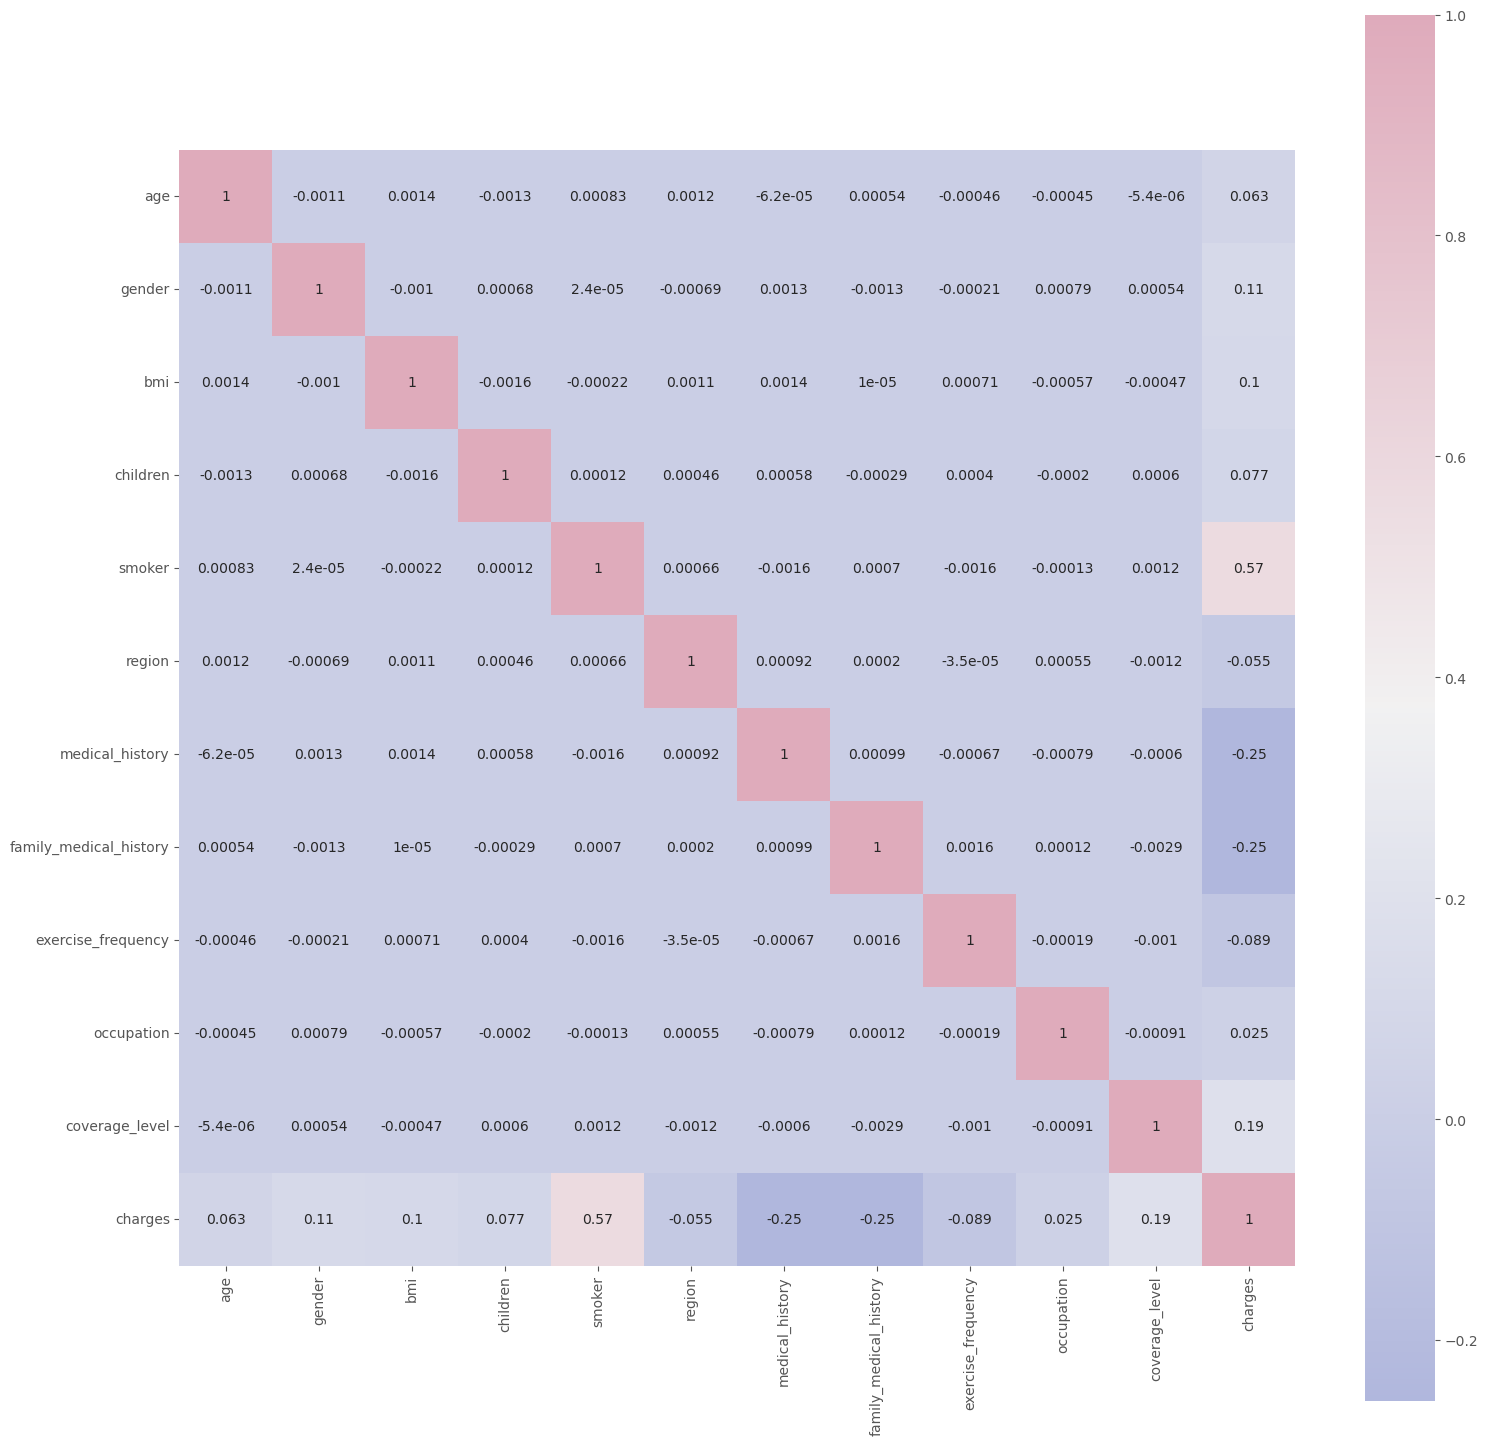

In [39]:
#Finding Correlation
cn=data.corr()
#Correlation 
cmap=sns.diverging_palette(260,-10,s=50, l=75, n=6,
as_cmap=True)
plt.subplots(figsize=(18,18))
sns.heatmap(cn,cmap=cmap,annot=True, square=True)
plt.show()

In [40]:
corr_matrix = data.corr()

corr_matrix["charges"].sort_values(ascending=False)

charges                   1.000000
smoker                    0.566213
coverage_level            0.186725
gender                    0.113526
bmi                       0.104429
children                  0.076801
age                       0.063390
occupation                0.025320
region                   -0.055433
exercise_frequency       -0.089342
family_medical_history   -0.253870
medical_history          -0.254810
Name: charges, dtype: float64

every feature is important although the significance levels differ

## Modeling

In [41]:
# Machine learning algorithms
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBRegressor

# Model evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_squared_log_error, mean_absolute_percentage_error


splitting data

In [42]:
from sklearn.model_selection import train_test_split

In [43]:
X = scaled_df.drop('charges', axis=1)
y = scaled_df['charges']

In [44]:
X.shape

(1000000, 11)

In [45]:
y.shape

(1000000,)

In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [47]:
# Print the results to verify the split
print("X_train:\n", X_train.shape)
print("X_test:\n", X_test.shape)
print("y_train:\n", y_train.shape)
print("y_test:\n", y_test.shape)

X_train:
 (800000, 11)
X_test:
 (200000, 11)
y_train:
 (800000,)
y_test:
 (200000,)


In [48]:
X_train.head()

,gender,coverage_level,occupation,smoker,region,medical_history,family_medical_history,exercise_frequency,age,bmi,children
566853,0,1,2,0,0,2,2,0,1.191231,0.905379,2
382311,1,1,3,0,0,1,1,1,0.613829,1.104692,2
241519,1,1,1,1,2,3,3,0,-1.551425,0.739645,0
719220,0,0,2,0,2,3,2,2,-1.623601,0.871799,0
905718,0,1,2,1,1,3,2,3,-0.540973,-1.055262,5


In [49]:
y_train.head()

566853    15219.853392
382311    24263.549328
241519    18818.122280
719220     6530.689260
905718    16826.465512
Name: charges, dtype: float64

#### Linear regression

In [50]:
# Step 4: Initialize the Linear Regression model
linear_regressor = LinearRegression()

# Step 5: Fit the model to the training data
linear_regressor.fit(X_train, y_train)

# Step 6: Predict the target on the test data
y_pred = linear_regressor.predict(X_test)

# Step 7: Calculate the performance metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
msle = mean_squared_log_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("R-squared (R²) Score:", r2)
print("Mean Squared Log Error (MSLE):", msle)
print("Mean Absolute Percentage Error (MAPE):", mape)

Mean Squared Error (MSE): 9157484.04608023
Mean Absolute Error (MAE): 2472.4665104091887
R-squared (R²) Score: 0.5294375997176279
Mean Squared Log Error (MSLE): 0.0356973262229114
Mean Absolute Percentage Error (MAPE): 0.1589051114489189


Decision Tree Regressor

In [51]:
# Step 4: Initialize the Decision Tree Regressor model
tree_regressor = DecisionTreeRegressor(random_state=42)

# Step 5: Fit the model to the training data
tree_regressor.fit(X_train, y_train)

# Step 6: Predict the target on the test data
y_pred = tree_regressor.predict(X_test)

# Step 7: Calculate the performance metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
msle = mean_squared_log_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("R-squared (R²) Score:", r2)
print("Mean Squared Log Error (MSLE):", msle)
print("Mean Absolute Percentage Error (MAPE):", mape)

Mean Squared Error (MSE): 260622.549421242
Mean Absolute Error (MAE): 409.2203712788874
R-squared (R²) Score: 0.9866077656476109
Mean Squared Log Error (MSLE): 0.0011957260741667177
Mean Absolute Percentage Error (MAPE): 0.026470088957100367


Random Forest Regressor

In [52]:
# Step 4: Initialize the Random Forest Regressor model
forest_regressor = RandomForestRegressor(random_state=42)

# Step 5: Fit the model to the training data
forest_regressor.fit(X_train, y_train)

# Step 6: Predict the target on the test data
y_pred = forest_regressor.predict(X_test)

# Step 7: Calculate the performance metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
msle = mean_squared_log_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("R-squared (R²) Score:", r2)
print("Mean Squared Log Error (MSLE):", msle)
print("Mean Absolute Percentage Error (MAPE):", mape)

Mean Squared Error (MSE): 131325.05010583627
Mean Absolute Error (MAE): 297.8898293650301
R-squared (R²) Score: 0.9932517894124581
Mean Squared Log Error (MSLE): 0.0006015836400746306
Mean Absolute Percentage Error (MAPE): 0.019271754265229694


Gradient Boosting Regressor

In [53]:
# Step 4: Initialize the Gradient Boosting Regressor model
gb_regressor = GradientBoostingRegressor(random_state=42)

# Step 5: Fit the model to the training data
gb_regressor.fit(X_train, y_train)

# Step 6: Predict the target on the test data
y_pred = gb_regressor.predict(X_test)

# Step 7: Calculate the performance metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
msle = mean_squared_log_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("R-squared (R²) Score:", r2)
print("Mean Squared Log Error (MSLE):", msle)
print("Mean Absolute Percentage Error (MAPE):", mape)

Mean Squared Error (MSE): 356467.48130484886
Mean Absolute Error (MAE): 476.5097493527139
R-squared (R²) Score: 0.981682720627046
Mean Squared Log Error (MSLE): 0.001613127162911232
Mean Absolute Percentage Error (MAPE): 0.030855832369975293


Support Vector Regressor

In [54]:
# Step 4: Initialize the SVR model
svr_regressor = SVR()

# Step 5: Fit the model to the training data
svr_regressor.fit(X_train, y_train)

# Step 6: Predict the target on the test data
y_pred = svr_regressor.predict(X_test)

# Step 7: Calculate the performance metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
msle = mean_squared_log_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("R-squared (R²) Score:", r2)
print("Mean Squared Log Error (MSLE):", msle)
print("Mean Absolute Percentage Error (MAPE):", mape)

KNN Regressor

In [ ]:
# Step 4: Initialize the KNN regressor model
knn_regressor = KNeighborsRegressor()

# Step 5: Fit the model to the training data
knn_regressor.fit(X_train, y_train)

# Step 6: Predict the target on the test data
y_pred = knn_regressor.predict(X_test)

# Step 7: Calculate the performance metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
msle = mean_squared_log_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("R-squared (R²) Score:", r2)
print("Mean Squared Log Error (MSLE):", msle)
print("Mean Absolute Percentage Error (MAPE):", mape)

Mean Squared Error (MSE): 974496.056428601
Mean Absolute Error (MAE): 756.5445204322982
R-squared (R²) Score: 0.9499249792769193
Mean Squared Log Error (MSLE): 0.004238751896017406
Mean Absolute Percentage Error (MAPE): 0.04881307094907257
